## 파생변수 + scaling(복잡)

- TARGET ENCODING
    -  범주형 변수를 수치형으로 변환하는 기법 
    -  각 범주(category)에 해당하는 목표 변수(target)의 통계치(보통 평균)를 새로운 값으로 대체
    -  사용 : 주로 범주 수가 많아 One-Hot Encoding을 쓰기 부담스러운 경우나, 순서가 없는 범주형 데이터를 유의미한 수치로 바꾸고 싶을 때 사용

    - 장점
        - 차원 폭발 방지 : 새로운 변수가 하나만 생김
        - 범주 간 자연스러운 순서 반영 : 
        - 메모리 및 연산이 one-hot encoding 보다 낮음

    - 주의점
        - 데이터 누수(Data Leakage)
            - 전체 데이터의 ‘실제’ 평균을 그대로 쓰면, 검증·테스트 과정에서 미래 정보를 이미 쓴 셈이 되어 과적합 가능성이 커짐.
        - 해결방법
            - K-Fold 내부에서 학습 폴드(fold)만으로 평균을 계산하고, 검증 폴드에 적용
            - Smoothing: 각 범주의 샘플 수가 적으면 평균이 불안정하므로, 전체 평균과 섞어서 가중치 부여

    - Smoothing
        - 범주별 평균(𝜇ᵢ)과 전체 평균(𝜇₀)을, 카테고리 빈도(countᵢ)에 비례해 섞음
        



In [26]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder, FunctionTransformer,
    StandardScaler, PowerTransformer
)
from category_encoders import TargetEncoder
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve
)

# 1) 데이터 로드
df       = pd.read_csv('train.csv')
df_test  = pd.read_csv('test.csv')
X_raw    = df.drop(columns=['label'])
y        = df['label']
X_test_raw = df_test.copy()

# 2) 파생변수 생성 함수
def make_features(df):
    df = df.copy()
    # pdays: -1 → 999
    df['pdays'] = df['pdays'].replace(-1, 999)
    # month → 숫자
    month_map = {
        'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
        'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12
    }
    df['month_num'] = df['month'].map(month_map)
    # 계절·휴가 플래그
    df['is_summer']   = df['month_num'].isin([6,7,8,9]).astype(int)
    df['is_winter']   = df['month_num'].isin([12,1]).astype(int)
    df['is_vacation'] = df['month_num'].isin([6,7,8,12,1]).astype(int)
    # 결합 변수, 구간화
    df['job_education'] = df['job'] + '_' + df['education']
    df['age_bin'] = pd.cut(
        df['age'], bins=[18,25,35,45,60,100],
        labels=['18-25','26-35','36-45','46-60','60+']
    )
    # 로그 변환 (balance): shift to avoid negative
    shift = max(0, 1 - df['balance'].min())
    df['log_balance'] = np.log1p(df['balance'] + shift)
    # 차이, 성공 여부, 추가 파생
    df['pdays_minus_previous']  = df['pdays'] - df['previous']
    df['is_poutcome_success']   = (df['poutcome']=='success').astype(int)
    df['duration_per_campaign'] = df['duration'] / (df['campaign'] + 1)
    df['day_of_year']           = df['day'] + (df['month_num'] - 1) * 30
    return df

# 3) 원본 데이터에 파생변수 적용
X_feat      = make_features(X_raw)
X_test_feat = make_features(X_test_raw)

# 4) Train/Val split
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_feat, y, test_size=0.2, stratify=y, random_state=42
)

# 5) TargetEncoding 먼저 수행 (y 필요)
job_te     = TargetEncoder()
pout_te    = TargetEncoder()

X_train_raw['job_te']  = job_te.fit_transform(X_train_raw['job'],  y_train)
X_train_raw['pout_te'] = pout_te.fit_transform(X_train_raw['poutcome'], y_train)

# val/test 데이터에도 transform만
X_val_raw['job_te']      = job_te.transform(X_val_raw['job'])
X_val_raw['pout_te']     = pout_te.transform(X_val_raw['poutcome'])
X_test_feat['job_te']    = job_te.transform(X_test_feat['job'])
X_test_feat['pout_te']   = pout_te.transform(X_test_feat['poutcome'])

# 6) 전처리 파이프라인 정의

# 6-1) 수치형 파이프라인
numeric_cols = [
    'age','log_balance','duration','campaign','previous',
    'pdays','pdays_minus_previous','duration_per_campaign',
    'day_of_year','job_te','pout_te'
]
num_transformer = ColumnTransformer([
    ('std_age',   StandardScaler(),                    ['age']),
    ('power_lb',  PowerTransformer(method='yeo-johnson'), ['log_balance']),
    ('power_dur', PowerTransformer(method='yeo-johnson'), ['duration']),
    ('std_camp',  StandardScaler(),                    ['campaign']),
    ('power_prev',PowerTransformer(method='yeo-johnson'), ['previous']),
    ('std_pdays', StandardScaler(),                    ['pdays']),
    ('std_diff',  StandardScaler(),                    ['pdays_minus_previous']),
    ('std_dpc',   StandardScaler(),                    ['duration_per_campaign']),
    ('std_doy',   StandardScaler(),                    ['day_of_year']),
    ('std_job_te',StandardScaler(),                    ['job_te']),
    ('std_pout_te',StandardScaler(),                   ['pout_te'])
], remainder='drop')

# 6-2) 범주형 파이프라인
binary_cols = [
    'default','housing','loan',
    'is_summer','is_winter','is_vacation','is_poutcome_success'
]
other_cols = [
    'marital','contact','job_education','age_bin','month_num','education'
]
cat_transformer = ColumnTransformer([
    ('bin_ohe',     OneHotEncoder(drop='if_binary', sparse_output=False), binary_cols),
    ('ohe_other',   OneHotEncoder(handle_unknown='ignore', sparse_output=False), other_cols)
], remainder='drop')

# 7) 훈련 데이터 전처리 & SMOTEENN
X_tr_num = num_transformer.fit_transform(X_train_raw)
X_tr_cat = cat_transformer.fit_transform(X_train_raw)
X_tr_enc = np.hstack([X_tr_num, X_tr_cat])

smote_enn      = SMOTEENN(random_state=42)
X_train_res, y_train_res = smote_enn.fit_resample(X_tr_enc, y_train)

# 8) 모델 학습
with open("best_params.json","r") as f:
    best_params = json.load(f)

model = LGBMClassifier(**best_params, random_state=42)
model.fit(X_train_res, y_train_res)


[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Info] Number of positive: 21901, number of negative: 18018
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006066 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `for

LGBMClassifier(model__boosting_type='gbdt', model__colsample_bytree=1,
               model__learning_rate=0.01, model__n_estimators=1000,
               model__num_leaves=64, model__subsample=0.5, random_state=42)

In [33]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# 1) 파생변수 생성 + 전처리 통합 파이프라인
preprocessor = Pipeline([
    # (A) 파생변수 생성
    ('feat', FunctionTransformer(make_features)),

    # (B) 숫자+범주형 전처리
    ('proc', ColumnTransformer([
        # 숫자형
        ('num', ColumnTransformer([
            ('std_age',   StandardScaler(),                    ['age']),
            ('power_lb',  PowerTransformer(method='yeo-johnson'), ['log_balance']),
            ('power_dur', PowerTransformer(method='yeo-johnson'), ['duration']),
            ('std_camp',  StandardScaler(),                    ['campaign']),
            ('power_prev',PowerTransformer(method='yeo-johnson'), ['previous']),
            ('std_pdays', StandardScaler(),                    ['pdays']),
            ('std_diff',  StandardScaler(),                    ['pdays_minus_previous']),
            ('std_dpc',   StandardScaler(),                    ['duration_per_campaign']),
            ('std_doy',   StandardScaler(),                    ['day_of_year']),
            ('std_job_te',StandardScaler(),                    ['job_te']),
            ('std_pout_te',StandardScaler(),                   ['pout_te'])
        ], remainder='drop'),
         # 숫자 컬럼들 (job_te, pout_te는 5) 포함
         ['age','log_balance','duration','campaign','previous',
          'pdays','pdays_minus_previous','duration_per_campaign',
          'day_of_year','job_te','pout_te']
        ),

        # 범주형
        ('cat', ColumnTransformer([
            ('bin_ohe',   OneHotEncoder(drop='if_binary', sparse_output=False),
                          ['default','housing','loan',
                           'is_summer','is_winter','is_vacation','is_poutcome_success']),
            ('ohe_other', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                          ['marital','contact','job_education','age_bin','month_num','education'])
        ], remainder='drop'),
         # 두 개의 그룹을 하나로
         ['default','housing','loan',
          'is_summer','is_winter','is_vacation','is_poutcome_success',
          'marital','contact','job_education','age_bin','month_num','education']
        )
    ], remainder='drop'))
])

# 2) 훈련/검증 전처리
X_train_enc = preprocessor.fit_transform(X_train_raw)
X_val_enc   = preprocessor.transform(X_val_raw)

# 3) SMOTEENN 적용
smote_enn      = SMOTEENN(random_state=42)
X_train_res, y_train_res = smote_enn.fit_resample(X_train_enc, y_train)

# 4) 모델 학습
with open("best_params.json","r") as f:
    best_params = json.load(f)

model = LGBMClassifier(**best_params, random_state=42)
model.fit(X_train_res, y_train_res)

# 5) 평가 파트 (이전과 동일)
y_val_proba = model.predict_proba(X_val_enc)[:,1]
precisions, recalls, pr_thresholds = precision_recall_curve(y_val, y_val_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = pr_thresholds[np.argmax(f1_scores)]

print(f"Best Threshold: {best_threshold:.4f}, F1: {f1_scores.max():.4f}")

def evaluate(model, X_enc, y_true, threshold):
    proba = model.predict_proba(X_enc)[:,1]
    pred  = (proba >= threshold).astype(int)
    return {
        'Accuracy':  accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred),
        'Recall':    recall_score(y_true, pred),
        'F1':        f1_score(y_true, pred)
    }

train_metrics = evaluate(model, X_train_res, y_train_res, best_threshold)
val_metrics   = evaluate(model, X_val_enc, y_val, best_threshold)

print("훈련 데이터:", train_metrics)
print("검증 데이터:", val_metrics)


[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Info] Number of positive: 21901, number of negative: 18018
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006191 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `for

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [58]:
#훈련 데이터: {'Accuracy': 0.9797089105438513, 'Precision': 0.9952101432261095, 'Recall': 0.967672709008721, 'F1': 0.981248263728123}
#검증 데이터: {'Accuracy': 0.8976303317535546, 'Precision': 0.5520361990950227, 'Recall': 0.6594594594594595, 'F1': 0.6009852216748769}

## 파생변수 + scaling(간단)

In [37]:
import numpy as np
import pandas as pd
import json
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder, FunctionTransformer,
    StandardScaler, PowerTransformer
)
from imblearn.combine import SMOTETomek
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    precision_recall_curve, f1_score,
    accuracy_score, precision_score, recall_score
)

# 0) 데이터 & 파생함수
df        = pd.read_csv('train.csv')
df_test   = pd.read_csv('test.csv')
X_raw     = df.drop(columns=['label'])
y         = df['label']
X_test_raw= df_test.copy()

def make_features(df):
    df = df.copy()
    df['pdays'] = df['pdays'].replace(-1, 999)
    month_map = {m:i+1 for i,m in enumerate(
        ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
    )}
    df['month_num'] = df['month'].map(month_map)
    df['is_summer']   = df['month_num'].isin([6,7,8,9]).astype(int)
    df['is_winter']   = df['month_num'].isin([12,1]).astype(int)
    df['is_vacation'] = df['month_num'].isin([6,7,8,12,1]).astype(int)
    df['job_education'] = df['job'] + '_' + df['education']
    df['age_bin'] = pd.cut(
        df['age'], bins=[18,25,35,45,60,100],
        labels=['18-25','26-35','36-45','46-60','60+']
    )
    shift = max(0,1 - df['balance'].min())
    df['log_balance'] = np.log1p(df['balance'] + shift)
    df['pdays_minus_previous']  = df['pdays'] - df['previous']
    df['is_poutcome_success']   = (df['poutcome']=='success').astype(int)
    df['duration_per_campaign'] = df['duration'] / (df['campaign'] + 1)
    df['day_of_year']           = df['day'] + (df['month_num'] - 1) * 30
    return df

X_feat      = make_features(X_raw)
X_test_feat = make_features(X_test_raw)

# 1) Train/Val split
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_feat, y, test_size=0.2, stratify=y, random_state=42
)

# 2) 전처리 파이프라인: 숫자 + 범주 모두 원-핫
numeric_cols = [
    'age','log_balance','duration','campaign','previous',
    'pdays','pdays_minus_previous','duration_per_campaign','day_of_year'
]
binary_cols = [
    'default','housing','loan',
    'is_summer','is_winter','is_vacation','is_poutcome_success'
]
other_cat = [
    'marital','contact','job','poutcome',
    'job_education','age_bin','month_num','education'
]

preprocessor = Pipeline([
    ('features', FunctionTransformer(make_features)),
    ('transform', ColumnTransformer([
        ('num', Pipeline([
            ('scale', StandardScaler())
        ]), numeric_cols),
        ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), binary_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), other_cat)
    ], remainder='drop'))
])

# 3) 전체 train 데이터 전처리 후 CV 평가
X_all_enc = preprocessor.fit_transform(X_feat)
best_params = json.load(open("best_params.json"))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
base_model = LGBMClassifier(**best_params, random_state=42)

cv_scores = cross_val_score(
    base_model, X_all_enc, y,
    cv=skf, scoring='f1', n_jobs=-1
)
print("5-Fold CV F1 scores:", np.round(cv_scores,4))
print("Mean CV F1:", np.round(cv_scores.mean(),4))

import lightgbm as lgb
from lightgbm import LGBMClassifier, early_stopping
from imblearn.combine import SMOTETomek
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler, PowerTransformer
from sklearn.metrics import precision_recall_curve, f1_score, accuracy_score, precision_score, recall_score


# SMOTETomek 적용
smt = SMOTETomek(random_state=42)
X_train_enc = preprocessor.transform(X_train_raw)
X_val_enc   = preprocessor.transform(X_val_raw)
X_res, y_res = smt.fit_resample(X_train_enc, y_train)

# Early Stopping 콜백을 이용한 학습
final_model = LGBMClassifier(**best_params, random_state=42)

final_model.fit(
    X_res, y_res,
    eval_set=[(X_val_enc, y_val)],
    eval_metric='f1',
    callbacks=[early_stopping(stopping_rounds=50, verbose=True)]
)

# 최적 Threshold 계산 & 평가
y_val_proba = final_model.predict_proba(X_val_enc)[:,1]
precisions, recalls, thr = precision_recall_curve(y_val, y_val_proba)
f1s = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_thr = thr[np.argmax(f1s)]
print(f"\nBest Threshold: {best_thr:.3f}, F1: {f1s.max():.4f}")

def eval_thr(model, X_enc, y_true, threshold):
    p = (model.predict_proba(X_enc)[:,1] >= threshold).astype(int)
    return {
        'Accuracy':  accuracy_score(y_true, p),
        'Precision': precision_score(y_true, p),
        'Recall':    recall_score(y_true, p),
        'F1':        f1_score(y_true, p)
    }

print("Validation Metrics:", eval_thr(final_model, X_val_enc, y_val, best_thr))


[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Info] Number of positive: 2961, number of negative: 22356
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002778 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `forc

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parame

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__subsample
5-Fold CV F1 scores: [0.5752 0.552  0.527  0.5538 0.5704]
Mean CV F1: 0.5557
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning] Unknown parameter: model__learning_rate
[LightGBM] [Warning] Unknown parameter: model__boosting_type
[LightGBM] [Warning] Unknown parameter: model__subsample
[LightGBM] [Warning] Unknown parameter: model__colsample_bytree
[LightGBM] [Warning] Unknown parameter: model__n_estimators
[LightGBM] [Warning] Unknown parameter: model__num_leaves
[LightGBM] [Warning

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [57]:
#Validation Metrics: {'Accuracy': 0.8819905213270142, 'Precision': 0.4969801553062985, 'Recall': 0.7783783783783784, 'F1': 0.6066350710900474}

## duration 제외 모델링

- duration 제외해서 하이퍼 파라미터 튜닝(optuna)를 진행함.

- OPTUNA
    - 자동 하이퍼파라미터 탐색 라이브러리
    - 모델의 성능(예: F1-score)을 최대화하는 최적의 하이퍼파라미터 조합을 찾아줌
    - study라는 실험 단위를 만들고, objective(trial) 함수 안에서 탐색할 파라미터 공간을 정의한 뒤, 여러 번(n_trials) 호출하면서 성능을 평가→최고 기록을 반환
    - 일일이 그리드 조합을 짜지 않고도 효율적인 탐색 전략(TPE, CMA-ES 등)을 써서 훨씬 빨리 좋은 파라미터를 찾을 수 있음

- SMOTETomek
    - SMOTE + Tomek
        - SMOTE(Synthetic Minority Over-sampling Technique) : 소수 클래스 샘플들 사이에서 선형 보간으로 가상의 데이터를 생성
        - Tomek Link : 두 클래스 간 경계에 위치한 중복·잡음 샘플을 제거 => 클래스 간 경계를 더 명확하게 함
    - 따라서 두개를 같이 사용하게 되면 “소수 클래스 증식 → 경계 잡음 제거”가 가능하게 되어 균형 잡힌 데이터를 만들 수 있게 됨.

    - label = 1(가입) 경우가 드물면, 모델이 0(미가입)만 예측해도 높은 정확도가 나오기에 accuracy는 높지만 precision이 낮은 경우가 많기에 "소수 클래스(1)"를 늘리고 다수 클래스를 줄여서 균형을 맞추는 방법



In [ ]:
import numpy as np
import pandas as pd
import json
import optuna

from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler
from sklearn.feature_selection import RFECV
from lightgbm import LGBMClassifier
from imblearn.combine import SMOTETomek
from sklearn.metrics import precision_recall_curve, f1_score

# 0) 데이터 로드 & 피처 함수 정의 (make_features는 그대로 사용)
df        = pd.read_csv('train.csv')
df_test   = pd.read_csv('test.csv')
X_raw     = df.drop(columns=['label'])
y         = df['label']

def make_features(df):
    df = df.copy()
    df['pdays'] = df['pdays'].replace(-1, 999)
    month_map = {m:i+1 for i,m in enumerate(
        ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
    )}
    df['month_num'] = df['month'].map(month_map)
    df['is_summer']   = df['month_num'].isin([6,7,8,9]).astype(int)
    df['is_winter']   = df['month_num'].isin([12,1]).astype(int)
    df['is_vacation'] = df['month_num'].isin([6,7,8,12,1]).astype(int)
    df['job_education'] = df['job'] + '_' + df['education']
    df['age_bin'] = pd.cut(
        df['age'], bins=[18,25,35,45,60,100],
        labels=['18-25','26-35','36-45','46-60','60+']
    )
    shift = max(0,1 - df['balance'].min())
    df['log_balance'] = np.log1p(df['balance'] + shift)
    df['pdays_minus_previous']  = df['pdays'] - df['previous']
    df['is_poutcome_success']   = (df['poutcome']=='success').astype(in)
    df['day_of_year']           = df['day'] + (df['month_num'] - 1) * 30
    return df


# 1) 피처 생성
X_feat      = make_features(X_raw)

# 2) Train/Val 분할
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_feat, y, test_size=0.2, stratify=y, random_state=42
)

# 3) 전처리 파이프라인: duration 제거
numeric_cols = [
    'age','log_balance','campaign','previous',
    'pdays','pdays_minus_previous','duration_per_campaign','day_of_year'
]
binary_cols = [
    'default','housing','loan',
    'is_summer','is_winter','is_vacation','is_poutcome_success'
]
other_cat = [
    'marital','contact','job','poutcome',
    'job_education','age_bin','month_num','education'
]

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('scale', StandardScaler())
    ]), numeric_cols),
    ('bin', OneHotEncoder(drop='if_binary', sparse_output=False), binary_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), other_cat)
], remainder='drop')

# 4) Feature Selection: RFECV (LightGBM 기반, 5-폴드 CV, F1 스코어)
selector = RFECV(
    estimator=LGBMClassifier(random_state=42),
    step=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring='f1',
    n_jobs=-1,
)

# 5) 전체 Pipeline 구성
pipe = Pipeline([
    ('feat', FunctionTransformer(make_features)),   # 파생변수 생성
    ('pre', preprocessor),                         # 스케일링 & 인코딩
    ('sel', selector),                             # RFECV로 변수 선택
    ('clf', LGBMClassifier(random_state=42))       # 최종 분류기
])

In [ ]:
# 6) Hyperparameter Tuning with Optuna
def objective(trial):
    # 튜닝할 하이퍼파라미터 공간 정의
    param = {
        'clf__n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'clf__learning_rate': trial.suggest_loguniform('learning_rate', 1e-3, 1e-1),
        'clf__num_leaves': trial.suggest_int('num_leaves', 16, 128),
        'clf__colsample_bytree': trial.suggest_uniform('colsample_bytree', 0.5, 1.0),
        'clf__subsample': trial.suggest_uniform('subsample', 0.5, 1.0),
        'clf__min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
    }
    pipe.set_params(**param)
    
    # 내부 CV에서 F1 스코어로 평가
    scores = cross_val_score(
        pipe, X_train_raw, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='f1',
        n_jobs=-1
    )
    return scores.mean()

In [40]:
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("Best Optuna params:", study.best_params)
print("Best CV F1:", study.best_value)

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2025-05-26 00:43:36,302] A new study created in memory with name: no-name-41346a0b-e71e-468c-a05b-4a9ce122acc2
  0%|          | 0/30 [00:00<?, ?it/s]/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_17513/3906233113.py:98: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'clf__learning_rate': trial.suggest_loguniform('learning_rate', 1e-3, 1e-1),
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_17513/3906233113.py:100: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/opt

[LightGBM] [Info] Number of positive: 1896, number of negative: 14308
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14308
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1895, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14308
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Nu

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 1895, number of negative: 14307
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.082565 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1171
[LightGBM] [Info] Number of data points in the train set: 16202, number of used features: 99
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116961 -> initscore=-2.021530
[LightGBM] [Info] Start training from score -2.021530
[LightGBM] [Info] Number of positive: 1895, number of negative: 14307
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012062 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1168
[LightGBM] [Info] Number of data points in the train set: 16202, number of used features: 99
[LightGBM] [Info] [b

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted w

...

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001034 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1022
[LightGBM] [Info] Number of data points in the train set: 16203, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.117015 -> initscore=-2.021003
[LightGBM] [Info] Start training from score -2.021003
[LightGBM] [Info] Number of positive: 1896, number of negative: 14307
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010798 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1023
[LightGBM] [Info] Number of data points in the train set: 16203, number of used features: 24
[LightGBM] [Info] [b

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 1. Best value: 0.521444:   7%|▋         | 2/30 [1:09:24<16:11:38, 2082.10s/it]

[W 2025-05-26 01:53:00,493] Trial 2 failed with parameters: {'n_estimators': 627, 'learning_rate': 0.002835782116520645, 'num_leaves': 40, 'colsample_bytree': 0.5722789528426597, 'subsample': 0.8123911671014807, 'min_child_samples': 50} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/optuna/study/_optimize.py", line 197, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_17513/3906233113.py", line 107, in objective
    scores = cross_val_score(
             ^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/_param_validation.py", line 216, in wrapper
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 684, in cross_val_

KeyboardInterrupt: 

In [50]:
# 학습시간이 너무 많이 걸려 중간에 중단함

In [41]:
print("현재까지 best params:", study.best_params)



현재까지 best params: {'n_estimators': 382, 'learning_rate': 0.07944284948100452, 'num_leaves': 17, 'colsample_bytree': 0.8527359083571928, 'subsample': 0.7611757840014974, 'min_child_samples': 30}


In [48]:
best_params = {
    'n_estimators': 382,
    'learning_rate': 0.0794,
    'num_leaves': 17,
    'colsample_bytree': 0.8527,
    'subsample': 0.7612,
    'min_child_samples': 30
}

# 'clf' 단계 이름을 사용
prefixed = {f'clf__{k}': v for k,v in best_params.items()}
pipe.set_params(**prefixed)


Pipeline(steps=[('feat',
                 FunctionTransformer(func=<function make_features at 0x430700cc0>)),
                ('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'log_balance',
                                                   'campaign', 'previous',
                                                   'pdays',
                                                   'pdays_minus_previous',
                                                   'duration_per_campaign',
                                                   'day_of_year']),
                                                 ('bin',
                                                  OneHotEncoder(drop='if_binary',
                                                                sparse_output=False...
                                                   'poutcome', 'job_education',
                                                   'age_bin', 'month_num',
                                                   'education'])])),
                ('sel',
                 RFECV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                       estimator=LGBMClassifier(random_state=42), n_jobs=-1,
                       scoring='f1')),
                ('clf',
                 LGBMClassifier(colsample_bytree=0.8527, learning_rate=0.0794,
                                min_child_samples=30, n_estimators=382,
                                num_leaves=17, random_state=42,
                                subsample=0.7612))])

In [55]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTETomek
from sklearn.preprocessing import FunctionTransformer
from lightgbm import LGBMClassifier

# 1) imblearn Pipeline 정의
pipe = ImbPipeline(steps=[
    ('feat', FunctionTransformer(make_features, validate=False)),  # 파생변수 생성
    ('pre', preprocessor),                                         # 스케일링·인코딩
    ('smt', SMOTETomek(random_state=42)),                          # SMOTETomek 샘플링
    ('sel', selector),                                             # RFECV 피처 선택
    ('clf', LGBMClassifier(random_state=42))                       # 분류기
])

# 2) Optuna로 찾은 best_params
best_params = {
    'n_estimators':        382,
    'learning_rate':       0.07944284948100452,
    'num_leaves':          17,
    'colsample_bytree':    0.8527359083571928,
    'subsample':           0.7611757840014974,
    'min_child_samples':   30
}

# 3) 'clf__' 접두어 붙여서 파이프라인에 적용
prefixed = { f'clf__{k}': v for k, v in best_params.items() }
pipe.set_params(**prefixed)

# 4) 한 번에 fit() 호출
pipe.fit(X_train_raw, y_train)

# 5) 검증 데이터 예측 예시
y_val_proba = pipe.predict_proba(X_val_raw)[:, 1]


[LightGBM] [Info] Number of positive: 17848, number of negative: 17847
[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Number of positive: 17847, number of negative: 17848
[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.019352 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17831
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021836 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_c

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014198 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17787
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 17848, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.025864 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17807
[LightGBM] [Info] Number of data points in the train set: 35695, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500014 -> initscore

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted w

[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018748 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17784
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 17848, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014768 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17804
[LightGBM] [Info] Number of data points in the train set: 35695, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500014 -> initscore

...

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000275 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 255
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 1
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 22309, number of negative: 22309
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007480 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 18759
[LightGBM] [Info] Number of data points in the train set: 44618, number of used features: 107
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 22309, number of negative: 22309
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006918 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 18716
[LightGBM] [Info] Number of data points in the train set: 44618, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


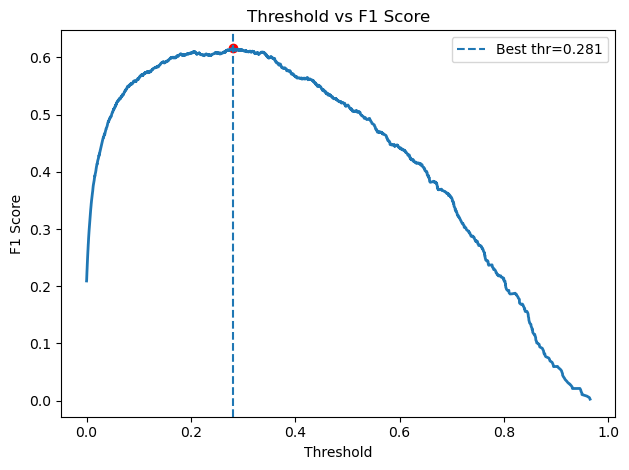

Threshold   F1 Score
    0.000   0.2093
    0.000   0.2096
    0.000   0.2099
    0.000   0.2102
    0.000   0.2105
    0.000   0.2108
    0.000   0.2111
    0.000   0.2114
    0.000   0.2117
    0.000   0.2120
    0.000   0.2123
    0.000   0.2126
    0.000   0.2129
    0.000   0.2133
    0.000   0.2136
    0.000   0.2139
    0.000   0.2142
    0.000   0.2145
    0.000   0.2148
    0.000   0.2151
    0.000   0.2154
    0.000   0.2157
    0.000   0.2161
    0.000   0.2164
    0.000   0.2167
    0.000   0.2170
    0.000   0.2173
    0.000   0.2176
    0.000   0.2180
    0.000   0.2183
    0.000   0.2186
    0.001   0.2190
    0.001   0.2193
    0.001   0.2196
    0.001   0.2199
    0.001   0.2203
    0.001   0.2206
    0.001   0.2209
    0.001   0.2213
    0.001   0.2216
    0.001   0.2219
    0.001   0.2223
    0.001   0.2226
    0.001   0.2229
    0.001   0.2233
    0.001   0.2236
    0.001   0.2239
    0.001   0.2243
    0.001   0.2246
    0.001   0.2250
    0.001   0.2253
    0.001 

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

# 1) 검증 데이터에 대한 예측 확률
#    pipe: imblearn Pipeline 또는 sklearn Pipeline (SMOTE+RFECV 포함) 객체
#    X_val_raw, y_val: train_test_split 으로 분리해둔 DataFrame과 시리즈
y_val_proba = pipe.predict_proba(X_val_raw)[:, 1]

# 2) Precision-Recall Curve 기반으로 임계값별 Precision, Recall, Thresholds 계산
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)

# 3) 각 임계값에 대응하는 F1 스코어 계산
#    thresholds 길이 = N, precisions/recalls 길이 = N+1 이므로 마지막 precision/recall은 threshold 없이 계산된 값
f1s = 2 * precisions * recalls / (precisions + recalls + 1e-9)

# 4) 그래프 그리기 (Threshold vs F1 Score)
plt.figure()
plt.plot(thresholds, f1s[:-1], lw=2)
best_idx = np.argmax(f1s[:-1])
best_thr = thresholds[best_idx]
best_f1 = f1s[:-1][best_idx]

plt.axvline(best_thr, linestyle='--', label=f'Best thr={best_thr:.3f}')
plt.scatter([best_thr], [best_f1], color='red')
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("Threshold vs F1 Score")
plt.legend()
plt.tight_layout()
plt.show()

# 5) 임계값별 F1 스코어 일부 값 확인
print("Threshold   F1 Score")
for thr, f1 in zip(thresholds[::10], f1s[:-1][::10]):  # 10개마다 샘플링
    print(f"{thr:>9.3f}   {f1:.4f}")

# 6) 최적 임계값과 F1 출력
print(f"\n▶ Best Threshold = {best_thr:.3f}, Best F1 = {best_f1:.4f}")


In [ ]:
# Best Threshold = 0.281, Best F1 = 0.6167

### LightGBM 복잡도 줄이기 + 정규화

In [59]:
# 1) imblearn Pipeline 정의
pipe = ImbPipeline(steps=[
    ('feat', FunctionTransformer(make_features, validate=False)),
    ('pre',  preprocessor),
    ('smt',  SMOTETomek(random_state=42)),
    ('sel',  selector),
    ('clf',  LGBMClassifier(random_state=42))
])

# 2) 수정된 best_params
best_params = {
    'n_estimators':      382,
    'learning_rate':     0.07944284948100452,
    'num_leaves':        8,
    'colsample_bytree':  0.8527359083571928,
    'subsample':         0.7611757840014974,
    'min_child_samples': 30,            
    'max_depth':         6,
    'reg_alpha':         1.0,
    'reg_lambda':        1.0
}

# 3) 'clf__' 접두어 붙여서 파이프라인에 적용
prefixed = { f'clf__{k}': v for k, v in best_params.items() }
pipe.set_params(**prefixed)

# 4) 한 번에 fit() 호출
pipe.fit(X_train_raw, y_train)

# 5) 검증 데이터 예측 예시
y_val_proba = pipe.predict_proba(X_val_raw)[:, 1]



[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Number of positive: 17847, number of negative: 17848[LightGBM] [Info] Number of positive: 17847, number of negative: 17847

[LightGBM] [Info] Number of positive: 17848, number of negative: 17847
[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023577 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17813
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.028247 seconds.
You can set `force_col_wise=true` to remove the overhead.

[LightGBM] [Info] Total Bins 17823
[LightGBM] [In

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Number of positive: 17847, number of negative: 17848
[LightGBM] [Info] Number of positive: 17848, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015814 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17775
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024392 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17773
[LightGBM] [Info] Number of data points in the train set: 35695, number of used features: 10

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020211 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17787
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


...

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17847, number of negative: 17847
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000494 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 255
[LightGBM] [Info] Number of data points in the train set: 35694, number of used features: 1
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 17847, number of negative: 17848
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000606 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 255
[LightGBM] [Info] Number of data points in the train set: 35695, number of used features: 1
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499986 -> initscore=-0.000056
[LightGBM] [Info] Start training from score -0.000056


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 22309, number of negative: 22309
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009680 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18759
[LightGBM] [Info] Number of data points in the train set: 44618, number of used features: 107
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 22309, number of negative: 22309
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006977 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 18716
[LightGBM] [Info] Number of data points in the train set: 44618, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 22309, number of

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


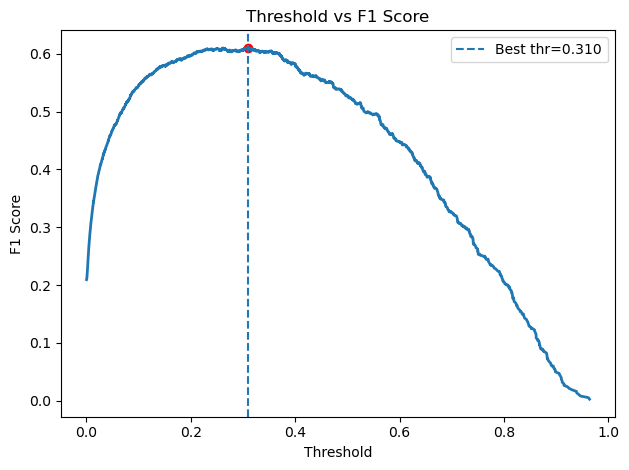

Threshold   F1 Score
    0.000   0.2093
    0.000   0.2096
    0.001   0.2099
    0.001   0.2102
    0.001   0.2105
    0.001   0.2108
    0.001   0.2111
    0.001   0.2114
    0.001   0.2117
    0.001   0.2120
    0.001   0.2123
    0.001   0.2126
    0.001   0.2129
    0.001   0.2133
    0.001   0.2136
    0.001   0.2139
    0.001   0.2142
    0.001   0.2145
    0.001   0.2148
    0.001   0.2151
    0.001   0.2154
    0.001   0.2157
    0.001   0.2161
    0.001   0.2164
    0.001   0.2167
    0.001   0.2170
    0.001   0.2173
    0.001   0.2176
    0.001   0.2180
    0.001   0.2180
    0.001   0.2183
    0.001   0.2187
    0.001   0.2190
    0.002   0.2193
    0.002   0.2196
    0.002   0.2200
    0.002   0.2203
    0.002   0.2206
    0.002   0.2210
    0.002   0.2213
    0.002   0.2216
    0.002   0.2220
    0.002   0.2223
    0.002   0.2226
    0.002   0.2230
    0.002   0.2233
    0.002   0.2236
    0.002   0.2240
    0.002   0.2243
    0.002   0.2247
    0.002   0.2251
    0.002 

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

# 1) 검증 데이터에 대한 예측 확률
#    pipe: imblearn Pipeline 또는 sklearn Pipeline (SMOTE+RFECV 포함) 객체
#    X_val_raw, y_val: train_test_split 으로 분리해둔 DataFrame과 시리즈
y_val_proba = pipe.predict_proba(X_val_raw)[:, 1]

# 2) Precision-Recall Curve 기반으로 임계값별 Precision, Recall, Thresholds 계산
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)

# 3) 각 임계값에 대응하는 F1 스코어 계산
#    thresholds 길이 = N, precisions/recalls 길이 = N+1 이므로 마지막 precision/recall은 threshold 없이 계산된 값
f1s = 2 * precisions * recalls / (precisions + recalls + 1e-9)

# 4) 그래프 그리기 (Threshold vs F1 Score)
plt.figure()
plt.plot(thresholds, f1s[:-1], lw=2)
best_idx = np.argmax(f1s[:-1])
best_thr = thresholds[best_idx]
best_f1 = f1s[:-1][best_idx]

plt.axvline(best_thr, linestyle='--', label=f'Best thr={best_thr:.3f}')
plt.scatter([best_thr], [best_f1], color='red')
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("Threshold vs F1 Score")
plt.legend()
plt.tight_layout()
plt.show()

# 5) 임계값별 F1 스코어 일부 값 확인
print("Threshold   F1 Score")
for thr, f1 in zip(thresholds[::10], f1s[:-1][::10]):  # 10개마다 샘플링
    print(f"{thr:>9.3f}   {f1:.4f}")

# 6) 최적 임계값과 F1 출력
print(f"\n▶ Best Threshold = {best_thr:.3f}, Best F1 = {best_f1:.4f}")


In [ ]:
#▶ Best Threshold = 0.310, Best F1 = 0.6102

### 클래스 가중치 적용

In [61]:
# 파이프라인에서 SMOTETomek 제거하고, LGBMClassifier에 class_weight만 줘보기
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine   import SMOTETomek

pipe_wt = ImbPipeline([
    ('feat', FunctionTransformer(make_features, validate=False)),
    ('pre', preprocessor),
    #('smt', SMOTETomek(random_state=42)),  # 제거
    ('sel', selector),  
    ('clf', LGBMClassifier(
        random_state=42,
        class_weight='balanced', 
        num_leaves=8,
        max_depth=6,
        reg_alpha=1.0,
        reg_lambda=1.0
    ))
])

pipe_wt.fit(X_train_raw, y_train)
# 평가
y_val_proba = pipe_wt.predict_proba(X_val_raw)[:,1]
prec, rec, thr = precision_recall_curve(y_val, y_val_proba)
f1s = 2*prec*rec/(prec+rec+1e-9)
i = f1s[:-1].argmax()
print("▶ class_weight ▶ F1:", f1s[:-1][i], "@thr=", thr[i])


[LightGBM] [Info] Number of positive: 2369, number of negative: 17884
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001319 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1180
[LightGBM] [Info] Number of data points in the train set: 20253, number of used features: 101
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116970 -> initscore=-2.021439
[LightGBM] [Info] Start training from score -2.021439
[LightGBM] [Info] Number of positive: 2370, number of negative: 17884
[LightGBM] [Info] Number of positive: 2369, number of negative: 17884
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001741 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1180
[LightGBM] [Info] Number of data points in

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 2369, number of negative: 17884
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003062 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1178
[LightGBM] [Info] Number of data points in the train set: 20253, number of used features: 100
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116970 -> initscore=-2.021439
[LightGBM] [Info] Start training from score -2.021439
[LightGBM] [Info] Number of positive: 2370, number of negative: 17884
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002861 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1184
[LightGBM] [Info] Number of data points in the train set: 20254, number of used features: 102
[LightGBM] [Info] 

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 2369, number of negative: 17884
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002804 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1182
[LightGBM] [Info] Number of data points in the train set: 20253, number of used features: 102
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116970 -> initscore=-2.021439
[LightGBM] [Info] Start training from score -2.021439


...

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 2370, number of negative: 17884
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000304 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 250
[LightGBM] [Info] Number of data points in the train set: 20254, number of used features: 1
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.117014 -> initscore=-2.021017
[LightGBM] [Info] Start training from score -2.021017
[LightGBM] [Info] Number of positive: 2370, number of negative: 17884
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000305 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 249
[LightGBM] [Info] Number of data points in the train set: 20254, number of used features: 1
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.117014 -> initscore=-2.021017
[LightGBM] [Info] Start training from score -2.021017


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001213 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1191
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116996 -> initscore=-2.021185
[LightGBM] [Info] Start training from score -2.021185
[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001078 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1189
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 104
[LightGBM] [Info] 

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [64]:
# 6) 오직 요약만 출력
print(f"[class_weight only] Best F1 = {best_f1:.4f} at Threshold = {best_thr:.3f}")

[class_weight only] Best F1 = 0.6102 at Threshold = 0.310


In [ ]:
#[class_weight only] Best F1 = 0.6102 at Threshold = 0.310

### SMOTE -> SMOTEEN

In [65]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.combine          import SMOTEENN

pipe_smoteenn = ImbPipeline([
    ('feat', FunctionTransformer(make_features, validate=False)),
    ('pre', preprocessor),
    ('smt', SMOTEENN(random_state=42)),  # SMOTE + ENN
    ('sel', selector),
    ('clf', LGBMClassifier(
        random_state=42,
        num_leaves=8, max_depth=6,
        reg_alpha=1.0, reg_lambda=1.0
    ))
])

pipe_smoteenn.fit(X_train_raw, y_train)
y_val_proba = pipe_smoteenn.predict_proba(X_val_raw)[:,1]
prec, rec, thr = precision_recall_curve(y_val, y_val_proba)
f1s = 2*prec*rec/(prec+rec+1e-9)
j = f1s[:-1].argmax()


[LightGBM] [Info] Number of positive: 17410, number of negative: 14307
[LightGBM] [Info] Number of positive: 17410, number of negative: 14307
[LightGBM] [Info] Number of positive: 17411, number of negative: 14307
[LightGBM] [Info] Number of positive: 17411, number of negative: 14307
[LightGBM] [Info] Number of positive: 17410, number of negative: 14308
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023921 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17772
[LightGBM] [Info] Number of data points in the train set: 31717, number of used features: 105
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023521 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17613
[LightGBM] [Info] [binary:Boo

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17410, number of negative: 14307
[LightGBM] [Info] Number of positive: 17410, number of negative: 14308
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.036593 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17736
[LightGBM] [Info] Number of data points in the train set: 31717, number of used features: 104
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548917 -> initscore=0.196296
[LightGBM] [Info] Start training from score 0.196296
[LightGBM] [Info] Number of positive: 17411, number of negative: 14307
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016582 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17726
[LightGBM] [Info] Number of data points

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17411, number of negative: 14307
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.017678 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 17744
[LightGBM] [Info] Number of data points in the train set: 31718, number of used features: 103
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548931 -> initscore=0.196353
[LightGBM] [Info] Start training from score 0.196353


...

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 17411, number of negative: 14307
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000208 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 255
[LightGBM] [Info] Number of data points in the train set: 31718, number of used features: 1
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548931 -> initscore=0.196353
[LightGBM] [Info] Start training from score 0.196353


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 21763, number of negative: 17884
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007870 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18676
[LightGBM] [Info] Number of data points in the train set: 39647, number of used features: 107
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548919 -> initscore=0.196305
[LightGBM] [Info] Start training from score 0.196305
[LightGBM] [Info] Number of positive: 21763, number of negative: 17884
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006948 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 18666
[LightGBM] [Info] Number of data points in the train set: 39647, number of used features: 106
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.548919 -> initscore=0.196305
[

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [66]:
print("▶ SMOTEENN ▶ F1:", f1s[:-1][j], "@thr=", thr[j])


▶ SMOTEENN ▶ F1: 0.5921855916902442 @thr= 0.654318771845989


In [ ]:
#print("▶ SMOTEENN ▶ F1:", f1s[:-1][j], "@thr=", thr[j])
